<a href="https://colab.research.google.com/github/nandu10l/Supervised_Learning_Assessment/blob/main/Supervised_Learning_Assessment_Nandagopan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA UNDERSTANDING

In [5]:
import pandas as pd

In [4]:
# to load the csv file
df = pd.read_csv("/content/drive/MyDrive/DSA/Datasets/bank_marketing_assessment_dataset.csv")


In [9]:
# to inspect its shape column names, data types and head()
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)
print("\nHead:")
df.head()

Shape: (600, 14)

Columns: ['customer_age', 'job', 'marital_status', 'education', 'account_balance', 'housing_loan', 'personal_loan', 'contact_type', 'contact_month', 'campaign_contacts', 'previous_contacts', 'engagement_score', 'annual_income_estimate', 'subscribed']

Data Types:
 customer_age                int64
job                        object
marital_status             object
education                  object
account_balance           float64
housing_loan               object
personal_loan              object
contact_type               object
contact_month              object
campaign_contacts           int64
previous_contacts           int64
engagement_score            int64
annual_income_estimate      int64
subscribed                 object
dtype: object

Head:


,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [10]:
# to identify the missing values present
missing_values = df.isnull().sum()
print("Missing Values:")
print(missing_values)

Missing Values:
customer_age               0
job                        0
marital_status             0
education                 15
account_balance           12
housing_loan               0
personal_loan              0
contact_type               9
contact_month              0
campaign_contacts          0
previous_contacts          0
engagement_score           0
annual_income_estimate     0
subscribed                 0
dtype: int64


In [15]:
# to check for duplicate rows
duplicate_rows = df[df.duplicated()]
print("\nDuplicate Rows:")
print(duplicate_rows)



Duplicate Rows:
Empty DataFrame
Columns: [customer_age, job, marital_status, education, account_balance, housing_loan, personal_loan, contact_type, contact_month, campaign_contacts, previous_contacts, engagement_score, annual_income_estimate, subscribed]
Index: []


In [17]:
# to report the target-class distribution
target_distribution = df['subscribed'].value_counts()
print("Target Distribution ('subscribed'):")
print(target_distribution)

Target Distribution ('subscribed'):
subscribed
no     426
yes    174
Name: count, dtype: int64


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

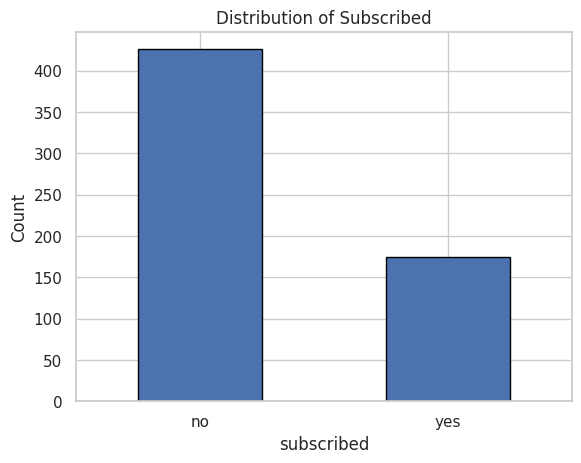

In [24]:
# Simple bar plot of target column distribution
df['subscribed'].value_counts().plot(kind='bar', edgecolor='black')
plt.title('Distribution of Subscribed')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

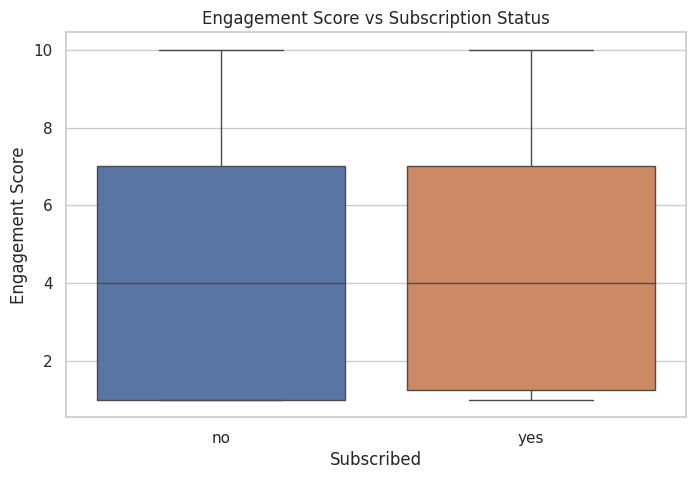

In [26]:
# Boxplot comparing engagement score by subscription status
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='subscribed', y='engagement_score', hue='subscribed', legend=False)
plt.title('Engagement Score vs Subscription Status')
plt.xlabel('Subscribed')
plt.ylabel('Engagement Score')
plt.show()

# DATA PREPARATION & FEATURE ENGINEERING

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate input features (X) and target (y)
X = df.drop(columns=['subscribed'])

# map target column if it is not numeric
if df['subscribed'].dtype == 'object':
    y = df['subscribed'].map({'yes': 1, 'no': 0})
else:
    y = df['subscribed']

# Train-test split(80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (480, 13)
Test set shape: (120, 13)


In [46]:
# Identify numeric and categorical features
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

# Preprocessing Pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Handle numeric missing values
    ('scaler', StandardScaler())                 # Scale numeric features
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), # Handle categorical missing values
    ('onehot', OneHotEncoder(handle_unknown='ignore'))   # One-hot encode
])

# Combine Preprocessors
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

In [47]:
print("Numeric Columns:", numeric_cols)
print("Categorical Columns:", categorical_cols)

Numeric Columns: ['customer_age', 'job', 'marital_status', 'education', 'account_balance', 'housing_loan', 'personal_loan', 'contact_type', 'contact_month', 'campaign_contacts', 'previous_contacts', 'engagement_score', 'annual_income_estimate']
Categorical Columns: []


# MODEL BUILDING

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [44]:
# Pipeline for Logistic Regression
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

# Build Pipeline for Random Forest
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_estimators=100))
])

# Fit models on training data only
lr_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)
print("Both pipelines fitted")

Both pipelines fitted


# MODEL EVALUATION & COMPARISON

In [51]:
# to print and evaluate the models accuracy, precision,, reall and F1-score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# predictions
y_pred_lr = lr_pipeline.predict(X_test)
y_pred_rf = rf_pipeline.predict(X_test)

# classification reports
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr, target_names= ['yes','no']))

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, y_pred_rf , target_names= ['yes','no']))


Logistic Regression Classification Report:
              precision    recall  f1-score   support

         yes       0.85      0.93      0.89        85
          no       0.78      0.60      0.68        35

    accuracy                           0.83       120
   macro avg       0.81      0.76      0.78       120
weighted avg       0.83      0.83      0.83       120


Random Forest Classification Report:
              precision    recall  f1-score   support

         yes       0.84      0.94      0.89        85
          no       0.80      0.57      0.67        35

    accuracy                           0.83       120
   macro avg       0.82      0.76      0.78       120
weighted avg       0.83      0.83      0.82       120



Model comparison Result

- Both Logistic Regression lassification and Randm-Forest classification models were build for comparison

- Random-forest Classification model is preffered as it provides an F1-score accuracy of '89%' and a recall value of '94%' while LR produced a recall-value of '93%'.
